# Fitting
To get Korg installed and talking to python, see [the installation documentation](https://ajwheeler.github.io/Korg.jl/stable/install/#Using-Korg-from-Python).

In this notebook, I'll show how to use `Korg.Fit.fit_spectrum` to fit one of the spectra from [Griffith et al. 2022](https://ui.adsabs.harvard.edu/abs/2022arXiv221001821G). You will probably find it helpful to look at the [documentation for this function](https://ajwheeler.github.io/Korg.jl/stable/API/#Korg.Fit.fit_spectrum) as well. For fitting equivalent widths (rather than spectra directly) see [the documentation for `Korg.Fit.ews_to_abundances`](https://ajwheeler.github.io/Korg.jl/stable/API/#Korg.Fit.ews_to_abundances). This notebook is intended to demonstrate the usages of Korg's fitting functionality, not an ironclad spectral analysis.

_A massive thanks to Emily Griffith for helping to translate this notebook into Python._

In [1]:
from matplotlib import pyplot as plt
from juliacall import Main as jl
import time
import random
import numpy as np
import pandas as pd

jl.seval("using Korg")
Korg = jl.Korg

Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython


In [2]:
from matplotlib import pyplot as plt
from juliacall import Main as jl
import time
import random
import numpy as np
import pandas as pd
from astropy.io import fits
import os
from astropy.table import Table
from functools import partial
from multiprocessing import Pool
import pickle

# import juliapkg
# juliapkg.add("Korg", "acafc109-a718-429c-b0e5-afd7f8c7ae46")
# juliapkg.resolve()

jl.seval("using Korg")
Korg = jl.Korg


def korg_fit(wave, flux, flux_err, line_list, params_fixed, resolution, windows, element, element_abund):
    
    # Defining the initial guesses
    print("Fitting %s..." % (element))
    guesses = {element: element_abund}
    
    t = time.process_time()
    fit_result = Korg.Fit.fit_spectrum(list(wave), list(flux), list(flux_err), line_list, guesses, params_fixed,
                                       R=resolution, windows=windows[Korg.atomic_numbers[element]])

    print(time.process_time() - t, " seconds")

    # return the best-fit abundance
    return fit_result


def run_korg(star_paths, linelist, params, windows):
    
    # Preparing the linelist
    j = 1
    process_id = os.getpid()
    for i, path in enumerate(star_paths):
        
        star_id = path.split('/')[-2]
        print('Running {0}\n- Process {1} \n- Star {2}/{3}\n'.format(star_id, process_id, j, len(star_paths)))
        j += 1
        
        # Finding and extracting the .fits data
        fits_file = path + star_id + '_data.fits'
        star_fits = fits.open(fits_file)
        
        uvb_data = star_fits[1].data
        uvb_wave = np.array(jl.broadcast(Korg.air_to_vacuum, uvb_data['wave'])) # Converting from air to vacuum
        uvb_flux = uvb_data['flux']
        uvb_flux_err = uvb_data['flux_err']
        
        vis_data = star_fits[2].data
        vis_wave = np.array(jl.broadcast(Korg.air_to_vacuum, vis_data['wave'])) # Converting from air to vacuum
        vis_flux = vis_data['flux']
        vis_flux_err = vis_data['flux_err']
        
        # uvb_data = pd.read_csv('/data/misfit/benlowe/xshooter/reduced_data/comb_spec/ra_0103-7050_s163/ra_0103-7050_s163_data.csv')
        # uvb_wave = np.array(jl.broadcast(Korg.air_to_vacuum, uvb_data.wave)) # Converting from air to vacuum
        # uvb_flux = np.array(uvb_data.flux)
        # uvb_flux_err = np.array(uvb_data.flux_err)
        
        
        # Getting the stellar parameters for the star
        star_params = params[params['star_id'] == star_id]
        params_dict = dict(Teff = star_params['teff'].to_numpy()[0],
                           logg = star_params['logg'].to_numpy()[0],
                           m_H = star_params['z'].to_numpy()[0])
        

        # Running Korg
        R_uvb = 5_600
        R_vis = 8900
        fit = korg_fit(wave=uvb_wave,
                       flux=uvb_flux,
                       flux_err=uvb_flux_err,
                       line_list=linelist,
                       params_fixed=params_dict,
                       resolution=R_uvb,
                       windows=windows,
                       element='Sr',
                       element_abund=0.1)
        
        return fit
        
        

# Loading in the data
# os.path.isdir(os.path.join(star_paths, star)) below is to ensure we're only looking at directories
star_paths = '/data/misfit/benlowe/xshooter/reduced_data/comb_spec/'
star_dirs = [star_paths + star + '/' for star in os.listdir(star_paths) if star == 'ra_0103-7050_s163'] #os.path.isdir(os.path.join(star_paths, star))
star_dirs.sort()

# Loading in the linelist and window table
linelist_path = '/data/misfit/benlowe/xshooter/linelist/lines.csv'
linelist_df = pd.read_csv(linelist_path)
linelist_df = linelist_df.sort_values('wave') # Sort by wavelength
window_path = '/data/misfit/benlowe/xshooter/linelist/lines_windows.csv'
window_df = pd.read_csv(window_path)


# Getting the linelist and windows into suitable format for Korg
print('Preparing linelist')
linelist_korg = jl.broadcast(Korg.Line, 
                            jl.broadcast(Korg.air_to_vacuum,linelist_df.wave),
                            linelist_df.loggf,
                            jl.broadcast(Korg.Species,linelist_df.species),
                            linelist_df.elow)

# Extracting the windows for each element
windows = {}
for i, row in window_df.iterrows():
    Z = Korg.get_atoms(Korg.Species(row.species))[0] # Getting atomic number for each element
    wins = windows.get(Z, []) # All windows with this element
    wins.append((Korg.air_to_vacuum(row.wavebase), Korg.air_to_vacuum(row.wavetop))) # Make a new window
    windows[Z] = wins # Update the dictionary
print('Done!')

# Loading in the stellar parameters from the AAT analysis
params_path = '/data/misfit/benlowe/xshooter/stellar_params/aat_params_FINAL.csv'
aat_pararms = pd.read_csv(params_path)

fit = run_korg(star_paths=star_dirs, linelist=linelist_korg, params=aat_pararms, windows=windows)
    

    
    
    
    



Preparing linelist
Done!
Running ra_0103-7050_s163
- Process 2097711 
- Star 1/1

Fitting Sr...
Constructing cool dwarf atmosphere interpolator.  This will only happen once per process...
726.822075662  seconds


In [ ]:
fit.best_fit_params

(best_fit_params = Dict("Sr" => -2.981297153327615), best_fit_flux = [0.9846383694464792, 0.9851645590252347, 0.9779917633699675, 0.9596832879378665, 0.9405518962935058, 0.9380556096043109, 0.9540206284613989, 0.9729014914749102, 0.9841652342656709, 0.9892480134880709, 0.9988740424521971, 0.9960350684757459, 0.9877154112157376, 0.9728951917723173, 0.9586633912969191, 0.9557669835586348, 0.9644402855013975, 0.974961744398778, 0.9823538677472663, 0.9885115300969122], obs_wl_mask = Bool[0, 0, 0, 0, 0, 0, 0, 0, 0, 0  …  0, 0, 0, 0, 0, 0, 0, 0, 0, 0], solver_result =  * Status: success

 * Candidate solution
    Final objective value:     9.470524e-08

 * Found with
    Algorithm:     BFGS

 * Convergence measures
    |x - x'|               = 7.91e-02 ≰ 1.0e-04
    |x - x'|/|x'|          = 1.89e+01 ≰ 0.0e+00
    |f(x) - f(x')|         = 6.44e-07 ≰ 0.0e+00
    |f(x) - f(x')|/|f(x')| = 6.80e+00 ≰ 0.0e+00
    |g(x)|                 = 3.35e-09 ≤ 1.0e-08

 * Work counters
    Seconds run:   259 

In [21]:
linelist_korg

2444-element Vector{Korg.Line{Float64, Float64, Float64, Float64, Float64, Float64}}:
 Fe I 3001.325781 Å (log gf = -1.1, χ = 1.49 eV)
 Co I 3001.422805 Å (log gf = -2.12, χ = 0.1 eV)
 Ca I 3001.737884 Å (log gf = -0.86, χ = 1.89 eV)
 Ti I 3001.739884 Å (log gf = -0.83, χ = 0.05 eV)
 Cr I 3001.758889 Å (log gf = -0.15, χ = 1.0 eV)
 Fe I 3001.822905 Å (log gf = -0.58, χ = 0.09 eV)
 V2 3002.078969 Å (log gf = 0.32, χ = 1.7 eV)
 Fe I 3002.620103 Å (log gf = -0.96, χ = 3.21 eV)
 Ni I 3003.360288 Å (log gf = -0.06, χ = 0.03 eV)
 Fe2 3003.520328 Å (log gf = -0.93, χ = 1.7 eV)
 ⋮
 Mg I 33199.99133 Å (log gf = 0.58, χ = 6.72 eV)
 Mg I 33970.841321 Å (log gf = -0.14, χ = 5.75 eV)
 Mg I 33971.267438 Å (log gf = -0.51, χ = 5.75 eV)
 Mg I 38667.999993 Å (log gf = 0.92, χ = 6.78 eV)
 Mg I 38668.180042 Å (log gf = 0.8, χ = 6.78 eV)
 Mg I 42012.642267 Å (log gf = 0.47, χ = 6.43 eV)
 Mg I 42013.274439 Å (log gf = 0.47, χ = 6.43 eV)
 Si I 54601.486541 Å (log gf = -0.08, χ = 5.96 eV)
 Si I 55850.072783 

## Read in the linelist, window list, and spectrum

For this example, we'll use the same linelist and windows as Griffith et al. 2022, which means reading the CSV files they are stored in and getting the data into the format expected by Korg.

In [2]:
# read and parse the linelist used by Griffith et al. 2022
linetable = pd.read_csv("lines.csv")

# filter out the H lines. (Korg has these built-in)
linetable = linetable[linetable.element != "H 1"]

In [3]:
linetable

,element,wave_A,loggf,lower_state_eV,rad,stark,waals
0,Ti 1,4200.019,-2.491,1.879,1.862087e+08,8.709636e-07,-7.68
1,Nd 2,4200.022,-1.640,0.064,NaN,NaN,NaN
2,W 1,4200.028,-0.990,2.037,NaN,NaN,NaN
3,U 2,4200.086,-1.467,0.779,NaN,NaN,NaN
4,Fe 1,4200.087,-1.130,3.884,5.011872e+07,8.709636e-06,-7.42
...,...,...,...,...,...,...,...
140287,Mn 2,9199.901,-0.709,13.441,1.023293e+08,2.089296e-03,-7.02
140288,Mn 2,9199.901,-0.248,13.441,1.023293e+08,2.089296e-03,-7.02
140289,Mn 2,9199.986,-1.618,13.441,1.023293e+08,2.089296e-03,-7.02
140290,Mn 2,9199.986,-0.731,13.441,1.023293e+08,2.089296e-03,-7.02


In [3]:
linelist = jl.broadcast(Korg.Line, 
                        jl.broadcast(Korg.air_to_vacuum,linetable.wave_A),
                        linetable.loggf,
                        jl.broadcast(Korg.Species,linetable.element),
                        linetable.lower_state_eV,
                        linetable.rad,
                        linetable.stark,
                        linetable.waals)


In [5]:
# read windows into dictionary that maps atomic number -> window list
windowtable = pd.read_csv("windows.tsv", delimiter='\t')

In [6]:
windowtable

,wave_peak,wave_base,wave_top,species
0,424.6822,424.6522,424.7122,Sc 2
1,432.0732,432.0432,432.1032,Sc 2
2,432.0950,432.0650,432.1250,Ti 2
3,433.1642,433.1342,433.1942,Ni 1
4,433.7046,433.6746,433.7346,Fe 1
...,...,...,...,...
395,625.2555,625.2255,625.2855,Fe 1
396,625.8102,625.7802,625.8402,Ti 1
397,625.8707,625.8407,625.9007,Ti 1
398,626.5132,626.4832,626.5432,Fe 1


In [33]:
windowtable['wave_top'].to_numpy() - windowtable['wave_base'].to_numpy()

array([0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06,
       0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06,
       0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06,
       0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06,
       0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06,
       0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06,
       0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06,
       0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06,
       0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06,
       0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06,
       0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06,
       0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06,
       0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06,
       0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.

In [7]:
windows = {}
for i, row in windowtable.iterrows():
    # atomic number
    Z = Korg.get_atoms(Korg.Species(row.species))[0]
    # get the windows for this element so far 
    wins = windows.get(Z, [])
    # add the new window
    wins.append((Korg.air_to_vacuum(row.wave_base * 10), Korg.air_to_vacuum(row.wave_top * 10)))
    # update the dictionary
    windows[Z] = wins
    

In [10]:
spec.waveobs

0        422.104886
1        422.108892
2        422.112897
3        422.116901
4        422.120904
            ...    
27964    631.649824
27965    631.655705
27966    631.661584
27967    631.667463
27968    631.673339
Name: waveobs, Length: 27969, dtype: float64

Text(0, 0.5, 'Normalized Flux')

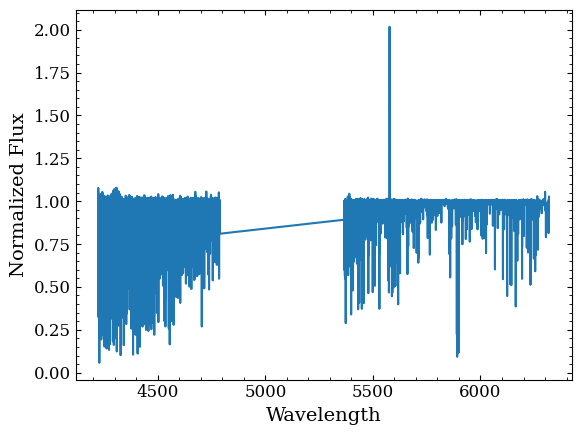

In [9]:
# parse the observed spectrum
spec = pd.read_csv("2MASS_J03443498+0553014.csv", delimiter="\t")

# juliacall deals better with numpy arrays than pandas series, so we will work with those
flux = np.array(spec.flux)
err = np.array(spec.err)
waveobs = np.array(jl.broadcast(Korg.air_to_vacuum, spec.waveobs * 10))

%matplotlib inline
plt.figure()
plt.plot(waveobs, flux)
plt.xlabel('Wavelength')
plt.ylabel('Normalized Flux')

# Get stellar params with just Fe lines
First, we'll use the Fe windows from `windows.tsv` to fit for the stellar parameters. You may notice that the first time you run this, it takes a minute.  This is because Julia is compiling the function. This happens only once per session. 

In [9]:
# provide an initial guess for each parameter we want to fit
# (This is how to construct a NamedTuple in Julia, by the way.)
initial_guess = dict(Teff=5400, logg=3.8, m_H=-1.1, vmic=1.0)
winds = windows[26] # use Fe windows

# In this example, we'll pass the spectral resolution R and let Korg take care of the line spread function automatically
# Below, I'll show how to speed things up by calculating it ahead of time.
fit_result = Korg.Fit.fit_spectrum(waveobs, flux, err, linelist, initial_guess, windows=winds, R=50_000)

`fit_result` is an object containing several bits of info, most importantly the best-fit parameters

In [16]:
fit_result.best_fit_params

Dict{String, Float64} with 4 entries:
  "Teff" => 5261.36
  "logg" => 3.68274
  "m_H"  => -1.33137
  "vmic" => 0.836878

It also contains the trace, which we can plot like so

Text(0.5, 0, 'optimizer step')

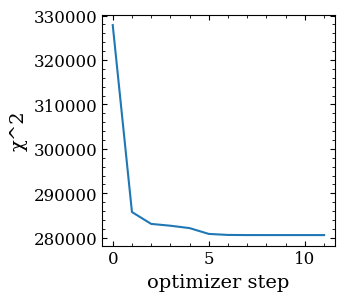

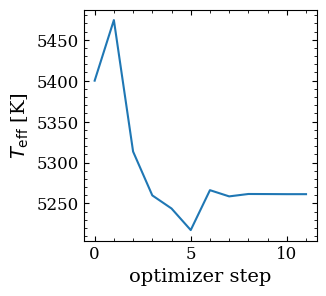

In [17]:
plt.figure(figsize=(3,3))
plt.plot([t["chi2"] for t in fit_result.trace])
plt.ylabel("χ^2")
plt.xlabel("optimizer step")

plt.figure(figsize=(3,3))
plt.plot([t["Teff"] for t in fit_result.trace])
plt.ylabel("$T_\mathrm{eff}$ [K]")
plt.xlabel("optimizer step")

The `fit_result` object also contains the best-fit spectrum, which we can plot in comparision to the oberved one.  Rerun the cell below to plot data for different iron lines.

In [ ]:
# get the observed spectrum only at the wavelengths within a fitting window
obsmask = np.array(fit_result.obs_wl_mask)
obs_wls = waveobs[obsmask]
obs_flux = flux[obsmask]
obs_err = err[obsmask]

w = random.choice(winds) # choose a window around a random Fe line

# create a bitmask to plot the window plus 1 Å on each side for context
mask = np.array((w[0]-1 < obs_wls) & (obs_wls < w[1]+1))

plt.plot(obs_wls[mask], np.array(fit_result.best_fit_flux)[mask], c="r", label="Korg")
plt.plot(obs_wls[mask], obs_flux[mask], c="k", label="data")
plt.legend()

NameError: name 'fit_result' is not defined

# Fit individual abundances

Let's use the stellar parameters from Griffith, rather than the ones from the analysis above. Comparing the abundances you get using each is left as an excercise to the reader.

In [18]:
griffith_params = dict(Teff = 5456, logg = 3.86, m_H = -1.22, vsini = 2.4, vmic=1.23)
# print(dict(fit_result.best_fit_params))
# print(griffith_params)

# Find individual abundances

In [20]:
def best_fit_abundance(element):
    print("fitting %s..." % (element))
        
    # use a Dict to store initial guesses at each param instead of a NamedTuple
    params = {element: griffith_params["m_H"]}

    # "params" specifies the initial guesses at the params to fit (in this case a single elemental abundance).
    # griffith_params specifies values which should be fixed (in this case the stellar parameters).
    t = time.process_time()
    fit_result = Korg.Fit.fit_spectrum(waveobs, flux, err, linelist, params, griffith_params, R=50_000, 
                                       windows=windows[Korg.atomic_numbers[element]])
    print(time.process_time() - t, " seconds")

    # return the best-fit abundance
    return fit_result.best_fit_params[element]


In [25]:
elements = ["Na", "Mg", "Si", "Ca", "Sc", "Ti", "V", "Cr", "Mn", "Fe", "Co", "Ni"]
Korg_abunds = [best_fit_abundance(e) for e in elements]

: 

: 

Let's plot these in comparison to the Griffith et al. 2022 abundaces.

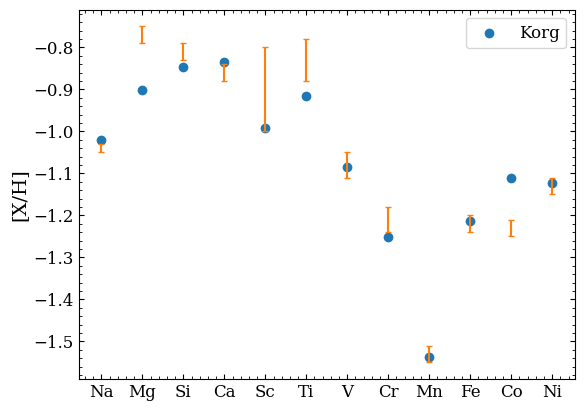

In [27]:
# The are the [X/H] values from the paper (and the errors inferred from Monte-Carlo)
griffith_X_H = [-1.04, -0.77, -0.81, -0.86, -0.9, -0.83, -1.08, -1.21, -1.53, -1.22, -1.23, -1.13]
griffith_X_H_err = [0.01, 0.02, 0.02, 0.02, 0.1, 0.05, 0.03, 0.03, 0.02, 0.02, 0.02, 0.02]

plt.scatter(range(len(elements)), Korg_abunds, label="Korg")
plt.errorbar(range(len(elements)), griffith_X_H, yerr=griffith_X_H_err, ls="", c="C1")
plt.xticks(range(len(elements)), elements)
plt.ylabel("[X/H]")
plt.legend()
